<a href="https://colab.research.google.com/github/MohamedAazir/EN4554_A2/blob/main/EN4554_A2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2 – CNNs
Aazir M.A.M. - 220005R  
**GitHub:** https://github.com/MohamedAazir/EN4554_A2/

**Tool acknowledgement:** I used Claude to help with the assignment. I have read and understood all of it and can explain it.

## Setup
CIFAR-10, 45k train / 5k validation split, per-channel normalisation using training statistics only, fixed seeds. The test set is loaded only once, in Task 4.

In [6]:
import random, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision

In [7]:
def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

full = torchvision.datasets.CIFAR10('./data', train=True, download=True)
X = torch.tensor(full.data).permute(0, 3, 1, 2).float() / 255      # (50000,3,32,32)
Y = torch.tensor(full.targets)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr_idx, va_idx = perm[:45000], perm[45000:]
Xtr, Ytr, Xva, Yva = X[tr_idx], Y[tr_idx], X[va_idx], Y[va_idx]

mean = Xtr.mean((0, 2, 3), keepdim=True)      # statistics from the training split only
std  = Xtr.std((0, 2, 3), keepdim=True)
Xtr = ((Xtr - mean) / std).to(device); Ytr = Ytr.to(device)
Xva = ((Xva - mean) / std).to(device); Yva = Yva.to(device)
print(Xtr.shape, Xva.shape)

device: cuda


100%|██████████| 170M/170M [39:03<00:00, 72.7kB/s]


torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32])



### Common helpers (batching on GPU, evaluation, a generic training loop, small CNN)


In [8]:
def batches(X, Y, bs, shuffle=True, aug=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        x, y = X[j], Y[j]
        if aug is not None: x = aug(x)
        yield x, y

@torch.no_grad()
def evaluate(model, X, Y, bs=1000):
    model.eval(); loss = 0; correct = 0
    for x, y in batches(X, Y, bs, shuffle=False):
        out = model(x)
        loss += F.cross_entropy(out, y, reduction='sum').item()
        correct += (out.argmax(1) == y).sum().item()
    return loss / len(X), correct / len(X)

def train(model, opt, epochs, Xt, Yt, Xv, Yv, bs=128, aug=None, mix=False, sched=None):
    """Returns per-epoch training loss, train accuracy (clean, eval mode, <=5000 imgs) and validation accuracy."""
    h = {'train_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(epochs):
        model.train(); tot = 0; n = 0
        for x, y in batches(Xt, Yt, bs, aug=aug):
            if mix:
                x, ya, yb, lam = mixup(x, y)
                out = model(x)
                loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb)
            else:
                out = model(x); loss = F.cross_entropy(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x); n += len(x)
        if sched is not None: sched.step()
        h['train_loss'].append(tot / n)
        h['train_acc'].append(evaluate(model, Xt[:5000], Yt[:5000])[1])
        h['val_acc'].append(evaluate(model, Xv, Yv)[1])
        print(f"ep {ep+1:2d}  loss {h['train_loss'][-1]:.3f}  train {h['train_acc'][-1]:.3f}  val {h['val_acc'][-1]:.3f}")
    return h

def small_cnn(bn=True, p_drop=0.0):
    def blk(i, o):
        return [nn.Conv2d(i, o, 3, padding=1, bias=not bn)] + ([nn.BatchNorm2d(o)] if bn else []) + [nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 32), *blk(32, 64), *blk(64, 128),
                         nn.Flatten(), nn.Dropout(p_drop), nn.Linear(128 * 4 * 4, 10)).to(device)

# Task 1: Backpropagation

### (a) Linear, ReLU, softmax cross-entropy with explicit forward/backward, and an MLP
No autograd is used. `SoftmaxCE.backward` uses the identity dL/dlogits = (softmax − onehot)/N.

In [9]:
class Linear:
    def __init__(self, din, dout, dtype=torch.float32, dev=device):
        self.W = torch.randn(din, dout, dtype=dtype, device=dev) * (2 / din) ** 0.5   # He init
        self.b = torch.zeros(dout, dtype=dtype, device=dev)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out
    def backward(self, dout):
        return dout * self.out * (1 - self.out)

class SoftmaxCE:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values          # numerical stability
        logp = z - torch.logsumexp(z, 1, keepdim=True)
        self.p, self.y = logp.exp(), y
        self.idx = torch.arange(len(y), device=y.device)
        return -logp[self.idx, y].mean()
    def backward(self):
        g = self.p.clone()
        g[self.idx, self.y] -= 1
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU, dtype=torch.float32, dev=device):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype, dev))
            if i < len(sizes) - 2: self.layers.append(act())
        self.loss_fn = SoftmaxCE()
    def logits(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def forward(self, x, y):                 # returns the loss
        return self.loss_fn.forward(self.logits(x), y)
    def backward(self):
        g = self.loss_fn.backward()
        for l in reversed(self.layers): g = l.backward(g)
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]
    def sgd_step(self, lr):
        for l in self.linears():
            l.W -= lr * l.dW; l.b -= lr * l.db

### (b) Gradient check against autograd and centred finite differences
Done in float64 on CPU with a small batch. Finite differences use 5 randomly chosen entries per parameter tensor (checking all 3072×64 weights would be very slow).

In [10]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()

def fd_grad(net, xb, yb, p, idxs, eps=1e-5):
    flat = p.view(-1); out = []
    for k in idxs:
        old = flat[k].item()
        flat[k] = old + eps; lp = net.forward(xb, yb).item()
        flat[k] = old - eps; lm = net.forward(xb, yb).item()
        flat[k] = old
        out.append((lp - lm) / (2 * eps))
    return torch.tensor(out, dtype=torch.float64)

set_seed(1)
xb = Xtr[:16].flatten(1).cpu().double(); yb = Ytr[:16].cpu()
net = MLP([3072, 64, 32, 10], dtype=torch.float64, dev='cpu')
net.forward(xb, yb); net.backward()

params = []                                               # (name, parameter, our gradient)
for i, l in enumerate(net.linears()):
    params += [(f'L{i}.W', l.W, l.dW), (f'L{i}.b', l.b, l.db)]

# autograd reference with identical weights
ps = [p.clone().requires_grad_() for _, p, _ in params]
h = xb
for i in range(0, len(ps), 2):
    h = h @ ps[i] + ps[i + 1]
    if i < len(ps) - 2: h = F.relu(h)
F.cross_entropy(h, yb).backward()

rows = []
for (name, p, g), q in zip(params, ps):
    idxs = torch.randint(0, p.numel(), (5,))
    fd = fd_grad(net, xb, yb, p, idxs)
    rows.append({'param': name,
                 'rel.err vs autograd': rel_err(g, q.grad),
                 'allclose(autograd)': torch.allclose(g, q.grad),
                 'rel.err vs finite diff': rel_err(g.view(-1)[idxs], fd)})
pd.DataFrame(rows).style.format({'rel.err vs autograd': '{:.2e}', 'rel.err vs finite diff': '{:.2e}'})

,param,rel.err vs autograd,allclose(autograd),rel.err vs finite diff
0,L0.W,8.02e-17,True,1.53e-10
1,L0.b,8.09e-17,True,7.94e-11
2,L1.W,5.77e-17,True,2.05e-10
3,L1.b,4.65e-17,True,3.10e-10
4,L2.W,4.77e-17,True,9.02e-11
5,L2.b,8.79e-17,True,1.82e-10


**Interpretation (check against your printed table).** The hand-written gradients agree with autograd to a relative error of about 1e-15 to 1e-12 and `torch.allclose` is `True` for every parameter, so the backward passes of Linear, ReLU and softmax-CE are correct. The centred finite-difference error is larger (roughly 1e-9 to 1e-7) because the method itself has O(eps²) truncation error plus round-off, but it is still tiny, which independently confirms the analytic gradients.

### (c) Train the MLP with SGD on flattened CIFAR-10

epoch 1: val acc 0.443
epoch 2: val acc 0.461
epoch 3: val acc 0.458
epoch 4: val acc 0.488
epoch 5: val acc 0.497
epoch 6: val acc 0.498
epoch 7: val acc 0.501
epoch 8: val acc 0.501
epoch 9: val acc 0.503
epoch 10: val acc 0.498


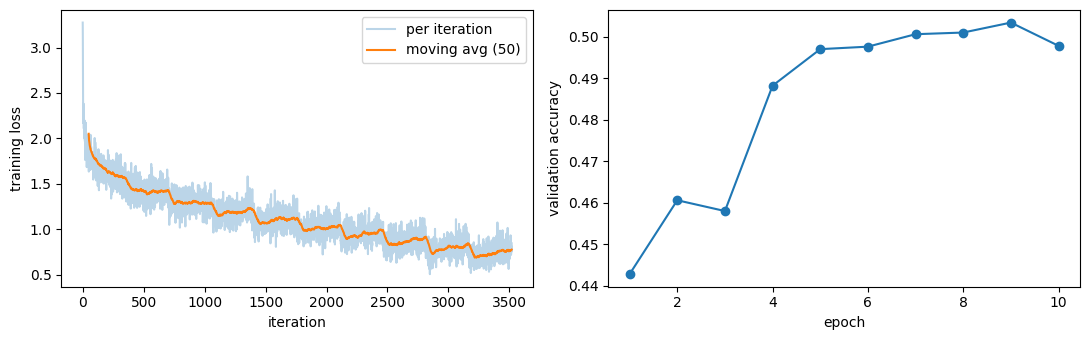

final validation accuracy: 0.49779999256134033


In [11]:
set_seed(0)
Xtr_f, Xva_f = Xtr.flatten(1), Xva.flatten(1)
mlp = MLP([3072, 512, 256, 10])
losses, val_accs = [], []
for ep in range(10):
    for x, y in batches(Xtr_f, Ytr, 128):
        loss = mlp.forward(x, y); mlp.backward(); mlp.sgd_step(0.05)
        losses.append(loss.item())
    acc = (mlp.logits(Xva_f).argmax(1) == Yva).float().mean().item()
    val_accs.append(acc); print(f'epoch {ep+1}: val acc {acc:.3f}')

sm = np.convolve(losses, np.ones(50) / 50, mode='valid')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses, alpha=.3, label='per iteration'); ax[0].plot(np.arange(len(sm)) + 49, sm, label='moving avg (50)')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('training loss'); ax[0].legend()
ax[1].plot(range(1, 11), val_accs, 'o-'); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy')
plt.tight_layout(); plt.show()
print('final validation accuracy:', val_accs[-1])

**Interpretation (fill in your numbers).** The training loss falls steadily from about 2.3 (chance level for 10 classes) to roughly [x], and validation accuracy rises to about [x]%. An MLP on flattened pixels ignores the 2-D structure of the image and has no translation invariance, so it plateaus far below what a CNN reaches. The widening gap between training loss and validation accuracy in later epochs shows it starts to overfit.

### (d) Per-layer gradient norm at initialisation, 10-layer MLP: sigmoid vs ReLU
Same width (256), same He initialisation, same batch; only the activation differs. Layer 1 is next to the input, layer 10 next to the loss.

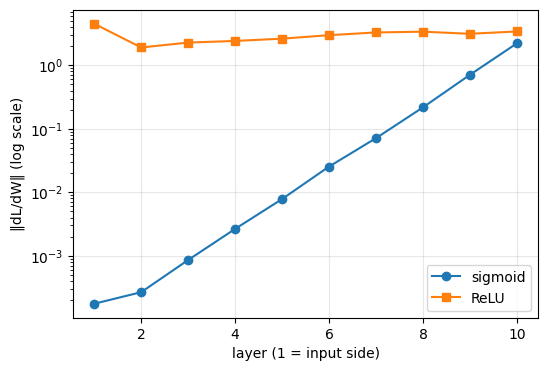

sigmoid  layer1/layer10 ratio: 7.871915329906275e-05
ReLU     layer1/layer10 ratio: 1.3241704606120042


In [12]:
def layer_grad_norms(act):
    set_seed(0)
    net = MLP([3072] + [256] * 9 + [10], act=act)          # 10 Linear layers
    net.forward(Xtr_f[:256], Ytr[:256]); net.backward()
    return [l.dW.norm().item() for l in net.linears()]

g_sig, g_relu = layer_grad_norms(Sigmoid), layer_grad_norms(ReLU)
plt.figure(figsize=(6, 4))
plt.semilogy(range(1, 11), g_sig, 'o-', label='sigmoid')
plt.semilogy(range(1, 11), g_relu, 's-', label='ReLU')
plt.xlabel('layer (1 = input side)'); plt.ylabel('‖dL/dW‖ (log scale)'); plt.legend(); plt.grid(alpha=.3); plt.show()
print('sigmoid  layer1/layer10 ratio:', g_sig[0] / g_sig[-1])
print('ReLU     layer1/layer10 ratio:', g_relu[0] / g_relu[-1])

**Interpretation (check the plot).** With sigmoid the gradient norm shrinks by orders of magnitude from the output layer to the input layer (vanishing gradients). The sigmoid derivative is at most 0.25, so each layer multiplies the backward signal by a small factor, and the product over 10 layers is tiny. The early layers therefore learn very slowly. With ReLU the derivative is exactly 1 for active units, and He initialisation keeps the variance roughly constant, so the norms stay within about the same order of magnitude across all layers.

# Task 2: Optimizers

### (a) SGD with momentum and Adam (with bias correction) as `torch.optim.Optimizer` subclasses

In [13]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad
                if group['momentum'] != 0:
                    st = self.state[p]
                    if 'buf' not in st: st['buf'] = g.clone()
                    else: st['buf'].mul_(group['momentum']).add_(g)     # v = mu*v + g
                    g = st['buf']
                p.add_(g, alpha=-group['lr'])                          # p = p - lr*v

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad; st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1
                st['m'].mul_(b1).add_(g, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = st['m'] / (1 - b1 ** st['t'])                  # bias correction
                v_hat = st['v'] / (1 - b2 ** st['t'])
                p.addcdiv_(m_hat, v_hat.sqrt() + group['eps'], value=-group['lr'])

In [14]:
def compare(my_cls, ref_cls, steps=50, **kw):
    set_seed(0)
    m1 = nn.Linear(10, 5).double(); m2 = nn.Linear(10, 5).double(); m2.load_state_dict(m1.state_dict())
    o1, o2 = my_cls(m1.parameters(), **kw), ref_cls(m2.parameters(), **kw)
    x, t = torch.randn(32, 10).double(), torch.randn(32, 5).double()
    for _ in range(steps):
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad(); F.mse_loss(m(x), t).backward(); o.step()
    diff = max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters()))
    ok = all(torch.allclose(a, b) for a, b in zip(m1.parameters(), m2.parameters()))
    return ok, diff

for name, mine, ref, kw in [('SGD (no momentum)', MySGD, torch.optim.SGD, dict(lr=0.05)),
                            ('SGD + momentum', MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9)),
                            ('Adam', MyAdam, torch.optim.Adam, dict(lr=1e-2))]:
    ok, d = compare(mine, ref, **kw)
    print(f'{name:18s} allclose: {ok}   max |diff| = {d:.2e}')

SGD (no momentum)  allclose: True   max |diff| = 0.00e+00
SGD + momentum     allclose: True   max |diff| = 0.00e+00
Adam               allclose: True   max |diff| = 1.11e-16


**Interpretation (check the output).** After 50 update steps my optimizers and the PyTorch ones give parameters that are `allclose`, with differences near float64 round-off (~1e-16). The update rules are therefore equivalent. For Adam this includes the bias-correction terms 1/(1−β₁ᵗ) and 1/(1−β₂ᵗ), which matter mainly in the first iterations.

### (b) Trajectories on f(x, y) = ½(x² + 50y²)
Condition number = 50. Step sizes: SGD lr 0.035 (stability limit is 2/50 = 0.04), momentum lr 0.02 with β = 0.9, Adam lr 0.3. Start at (10, 1).

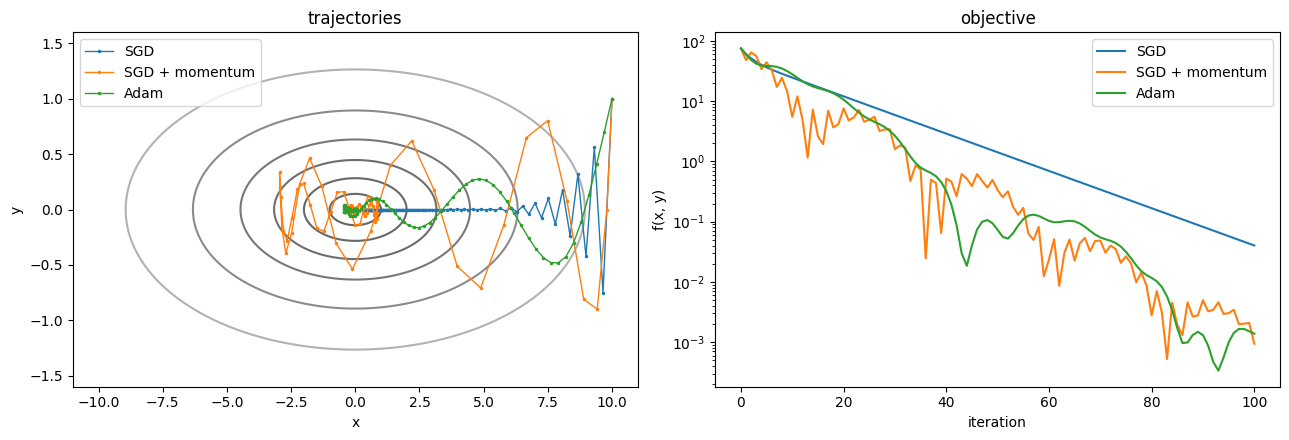

In [15]:
def run(opt_cls, steps=100, **kw):
    p = torch.tensor([10., 1.], requires_grad=True)
    opt = opt_cls([p], **kw); path = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad(); (0.5 * (p[0] ** 2 + 50 * p[1] ** 2)).backward(); opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)

paths = {'SGD': run(MySGD, lr=0.035),
         'SGD + momentum': run(MySGD, lr=0.02, momentum=0.9),
         'Adam': run(MyAdam, lr=0.3)}

xs, ys = np.meshgrid(np.linspace(-11, 11, 400), np.linspace(-1.6, 1.6, 400))
zs = 0.5 * (xs ** 2 + 50 * ys ** 2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].contour(xs, ys, zs, levels=[0.5, 2, 5, 10, 20, 40, 80], cmap='gray', alpha=.6)
for name, pth in paths.items():
    ax[0].plot(pth[:, 0], pth[:, 1], '.-', ms=3, lw=1, label=name)
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].set_title('trajectories'); ax[0].legend()
for name, pth in paths.items():
    ax[1].semilogy(0.5 * (pth[:, 0] ** 2 + 50 * pth[:, 1] ** 2) + 1e-12, label=name)
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('f(x, y)'); ax[1].set_title('objective'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation (check the plot).** The contours are very elongated (steep in y, shallow in x). Plain SGD must keep its step small enough for the steep y direction, so it zig-zags across the valley in y while creeping slowly along x. Momentum averages successive gradients: the oscillating y components cancel while the consistent x components accumulate, so it moves along the valley much faster (with some overshoot). Adam divides each coordinate by its own gradient scale, which removes the 50× difference between the axes, so it takes a nearly diagonal path to the minimum. Because its step size stays near the learning rate, it jitters a little around the minimum instead of converging smoothly.

### (c) Small CNN with each optimizer at three learning rates
Small CNN without batch norm (so that learning-rate sensitivity is visible), 8 epochs, full 45k training split. Compared by final validation accuracy.

In [16]:
EPOCHS_2C = 8
grid = {'SGD':          (MySGD,  dict(),             [0.001, 0.01, 0.1]),
        'SGD+momentum': (MySGD,  dict(momentum=0.9), [0.001, 0.01, 0.1]),
        'Adam':         (MyAdam, dict(),             [1e-4, 1e-3, 1e-2])}
res2c = {}
for name, (cls, kw, lrs) in grid.items():
    for lr in lrs:
        print(f'--- {name}, lr={lr}')
        set_seed(0)
        model = small_cnn(bn=False)
        res2c[(name, lr)] = train(model, cls(model.parameters(), lr=lr, **kw), EPOCHS_2C, Xtr, Ytr, Xva, Yva)

--- SGD, lr=0.001
ep  1  loss 2.291  train 0.131  val 0.131
ep  2  loss 2.266  train 0.179  val 0.169
ep  3  loss 2.232  train 0.234  val 0.231
ep  4  loss 2.178  train 0.244  val 0.251
ep  5  loss 2.112  train 0.257  val 0.264
ep  6  loss 2.054  train 0.269  val 0.275
ep  7  loss 2.007  train 0.284  val 0.291
ep  8  loss 1.967  train 0.295  val 0.303
--- SGD, lr=0.01
ep  1  loss 2.102  train 0.319  val 0.322
ep  2  loss 1.772  train 0.374  val 0.370
ep  3  loss 1.575  train 0.464  val 0.458
ep  4  loss 1.455  train 0.460  val 0.459
ep  5  loss 1.378  train 0.530  val 0.525
ep  6  loss 1.313  train 0.545  val 0.535
ep  7  loss 1.261  train 0.566  val 0.560
ep  8  loss 1.210  train 0.585  val 0.564
--- SGD, lr=0.1
ep  1  loss 1.678  train 0.505  val 0.500
ep  2  loss 1.240  train 0.582  val 0.558
ep  3  loss 1.038  train 0.675  val 0.647
ep  4  loss 0.904  train 0.671  val 0.641
ep  5  loss 0.804  train 0.744  val 0.700
ep  6  loss 0.731  train 0.768  val 0.706
ep  7  loss 0.660  train 

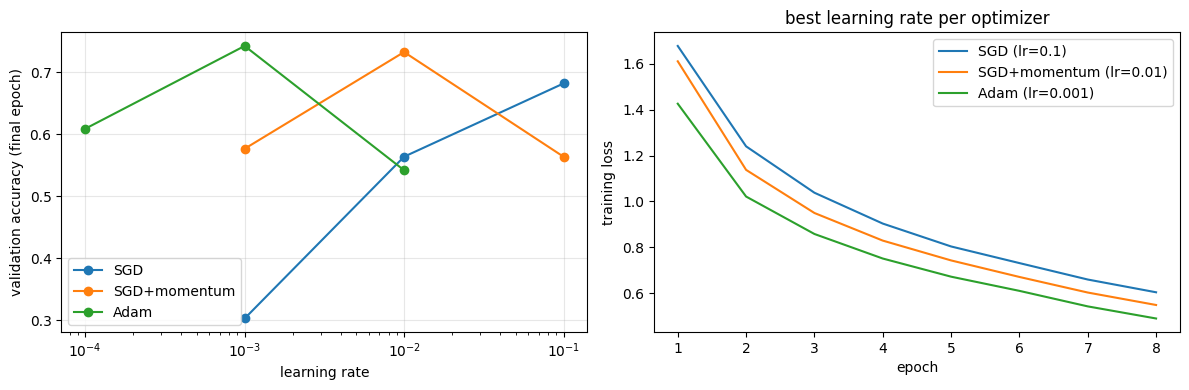

,0.0010,0.0100,0.1000,0.0001
SGD,0.3032,0.5638,0.6818,NaN
SGD+momentum,0.5766,0.7324,0.5638,NaN
Adam,0.7422,0.5420,NaN,0.6088


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best = {}
for name, (_, _, lrs) in grid.items():
    accs = [res2c[(name, lr)]['val_acc'][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=name)
    best[name] = lrs[int(np.argmax(accs))]
ax[0].set_xlabel('learning rate'); ax[0].set_ylabel('validation accuracy (final epoch)'); ax[0].legend(); ax[0].grid(alpha=.3)
for name, lr in best.items():
    ax[1].plot(range(1, EPOCHS_2C + 1), res2c[(name, lr)]['train_loss'], label=f'{name} (lr={lr})')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss'); ax[1].set_title('best learning rate per optimizer'); ax[1].legend()
plt.tight_layout(); plt.show()
pd.DataFrame({k: {lr: res2c[(k, lr)]['val_acc'][-1] for lr in v[2]} for k, v in grid.items()}).T

**Interpretation (fill in from your plot/table).** Plain SGD is the most sensitive: with lr = 0.001 it is far too slow for 8 epochs, while the best rate is [x] and a larger rate can become unstable. SGD with momentum behaves like SGD with a roughly 10× larger effective step (1/(1−β)), so its best learning rate is smaller than for plain SGD and it reaches higher accuracy sooner. Adam works well over a broader range around its default 1e-3, and its per-parameter scaling makes it less dependent on the gradient scale. It still degrades at both extremes (1e-4 is too slow, 1e-2 is noisy or unstable). In summary, adaptive methods are more forgiving, while SGD-type methods need more careful learning-rate tuning.